# Ingénierie des caractéristiques I

Ce notebook implémente les étapes demandées pour la **Partie 2** du Jalon 2

## 1. Organisation et partitionnement des données

Nous utilisons le fichier `data/processed/shots.csv` généré à l'Étape 1 qui contient déjà les tirs et buts extraits pour toutes les saisons 2016-2017 à 2023-2024.

Comme il est demandé, nous allons d'abord séparé les données en 3 ensembles fixes. 
- Test : On réserve la saison 2023/2024 pour les tests finaux
- Entraînement : On prend 80% dans les saisons restantes 
- Validation : On prend 20% dans les saisons restantes

In [27]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
from sklearn.model_selection import train_test_split
from ift6758.data_acquisition import PROJECT_ROOT
from ift6758.features.build_dataset import PROCESSED


data_path = PROJECT_ROOT / "data" / "processed" / "shots.csv"
df_all = pd.read_csv(data_path)

df_test_regular = df_all[(df_all["game_type"] == 2) & (df_all["season"] == 20232024)]
df_test_playoffs = df_all[(df_all["game_type"] == 3) & (df_all["season"] == 20232024)]

df_regular_dev = df_all[(df_all["game_type"] == 2) & (df_all["season"] != 20232024)]

# Ici on sépare les saisons réservées au développement en deux ensemble, on 
# doit s'assurer que les ensembles soient stratifiés sur is_goal pour ne pas 
# avoir de déséquilibre.
train_df, val_df = train_test_split(
    df_regular_dev,
    test_size=0.20,
    stratify=df_regular_dev['is_goal'],
    random_state=42
)

print("Proportion buts (Train) :", train_df['is_goal'].mean())
print("Proportion buts (Val)   :", val_df['is_goal'].mean())

PROCESSED.mkdir(parents=True, exist_ok=True)

csv_file = PROCESSED / 'test_regular_20232024.csv'
df_test_regular.to_csv(csv_file, index=False)

csv_file = PROCESSED / 'test_playoffs_20232024.csv'
df_test_playoffs.to_csv(csv_file, index=False)

csv_file = PROCESSED / 'train_set.csv'
train_df.to_csv(csv_file, index=False)

csv_file = PROCESSED / 'validation_set.csv'
val_df.to_csv(csv_file, index=False)

Proportion buts (Train) : 0.09736637600179261
Proportion buts (Val)   : 0.09736352800953516


Dans notre jeu de données train_df nous avons toutes les caractéristiques que build_dataset inclus. Autrement dit nous respectons avoir les caractéristiques shot_distance, shot_angle, is_goal, empty_net.
Pour le reste de la section, nous allons définir un dataframe qui contient simplement ces colonnes. On va aussi afficher les valeurs manquantes de chaque colonnes :

In [28]:
df_cols_imp_train = train_df[["shot_distance", "shot_angle", "is_goal", "empty_net"]].copy()

# On va transformer empty_net pour que ce soit 0 ou 1 au lieu de True or False
df_cols_imp_train["empty_net"] = df_cols_imp_train["empty_net"].map({True: 1, False: 0})

print("Nombre de valeurs manquantes par caractéristique :")
print(df_cols_imp_train.isna().sum())


print(df_cols_imp_train.head(10))

Nombre de valeurs manquantes par caractéristique :
shot_distance      97
shot_angle       2354
is_goal             0
empty_net        3242
dtype: int64
        shot_distance  shot_angle  is_goal  empty_net
519593      54.120237   27.512003        0        0.0
544388      33.970576   42.614056        0        0.0
114441      38.470768   27.897271        0        0.0
250681      52.886671   15.350136        0        0.0
299334      46.097722    3.731397        0        0.0
359252      10.440307   16.699244        0        0.0
494789      25.961510   15.642246        0        0.0
449900      58.600341   25.253163        0        0.0
240518      15.652476   63.434949        0        0.0
490113      15.524175   14.931417        0        0.0


On remarque que nous avons 97 données avec la distance manquante, 2354 avec l'angle manquant puis 3242 pour empty_net.

Maintenant, nous allons faire l'histogramme du nombre de tirs (buts et non-buts séparés), regroupés (binned) par distance. Après avoir essayé l'échelle normale, on voit que l'ordre de grandeur diffère beaucoup selon le résultats du tirs, dans ce cas le nombre de tirs subira une transformation logarithmique.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\carig\Docume

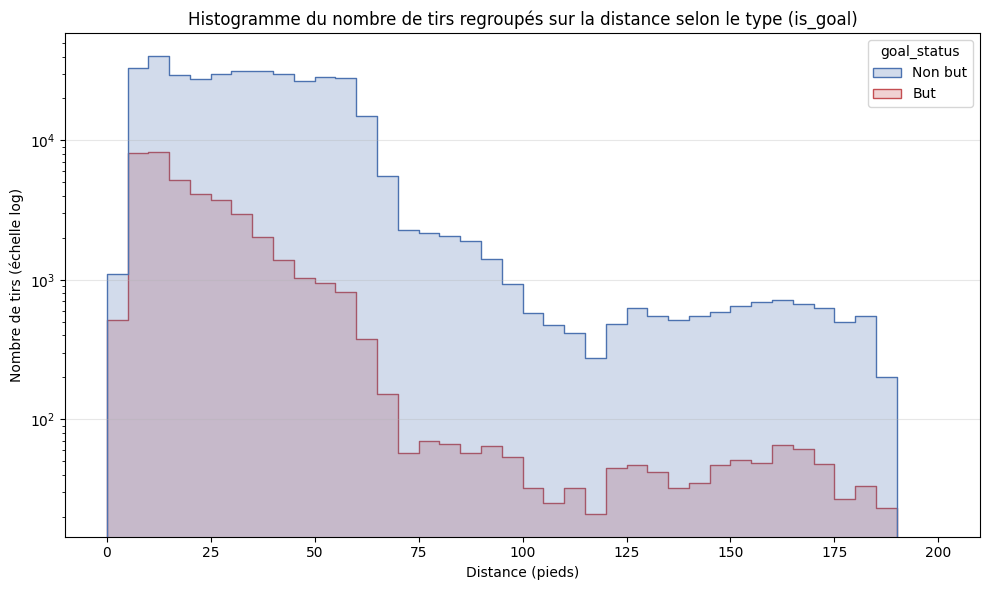

In [29]:
# Pour que ce soit plus clair on va mettre la légende de façon explicite
df_cols_imp_train["goal_status"] = df_cols_imp_train["is_goal"].map({0:"Non but", 1:"But"})
# On déclare une palette de couleur
colors = {"Non but": "#4C72B0", "But": "#C44E52"}
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    data=df_cols_imp_train,
    x="shot_distance",
    hue="goal_status",
    palette=colors,
    binwidth=5.0,
    binrange=(0, 200),
    element="step",
    ax=ax
)
ax.set_yscale("log")
ax.set_title("Histogramme du nombre de tirs regroupés sur la distance selon le type (is_goal)")
ax.set_xlabel("Distance (pieds)")
ax.set_ylabel("Nombre de tirs (échelle log)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

On voit qu'il y a énormément de tirs plus loin que 100 pieds, ce qui n'est pas anormal, mais il faudra être prudent. Des tirs qui sont des buts passé 100 pieds lorsque ce n'est pas en filet désert c'est plutôt rare. Peut-être que la fonction qui calcule le defending side s'est trompé, ce sera à investiguer. 

Maintenant, nous allons faire le même graphique mais regroupé par l'angle, nous allons aussi mettre l'échelle logarithmique.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\carig\Docume

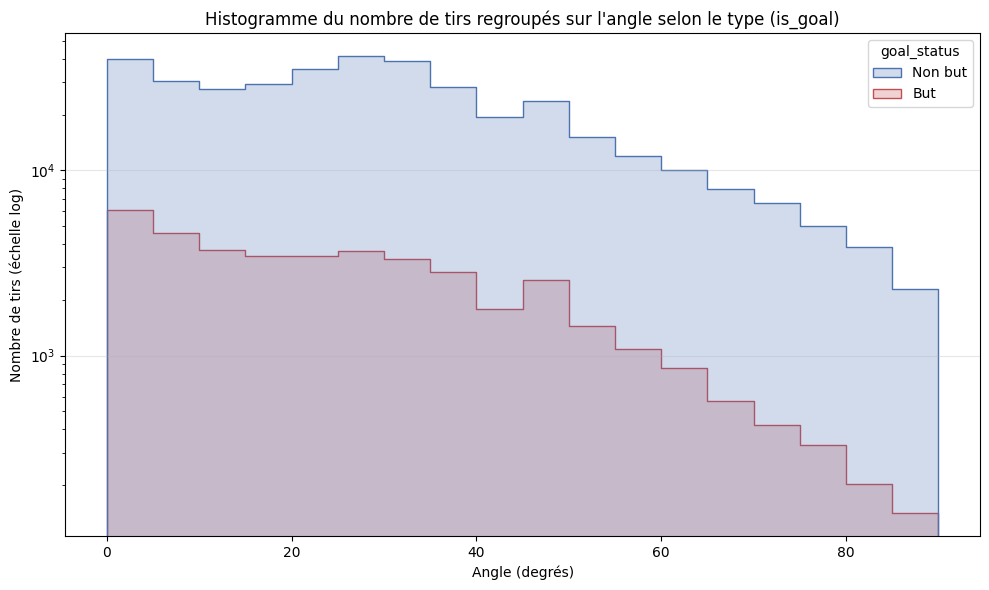

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    data=df_cols_imp_train,
    x="shot_angle",
    hue="goal_status",
    palette=colors,
    binwidth=5.0,
    binrange=(0, 90),
    element="step",
    ax=ax
)
ax.set_yscale("log")
ax.set_title("Histogramme du nombre de tirs regroupés sur l'angle selon le type (is_goal)")
ax.set_xlabel("Angle (degrés)")
ax.set_ylabel("Nombre de tirs (échelle log)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

On remarque que nous avons l'impression que plus le tir est décentré au filet plus le pourcentage de but semble descendre.

Nous allons maintenant faire l'histogramme en 2D ou un axe est la distance et l'autre l'angle. Nous utiliserons l'échelle logarithmique pour les couleurs aussi puisqu'il y a beaucoup plus de tirs proche du filet avec un angle de 0 que de tirs loins avec des angles élevés.

c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\carig\Documents\GitHub\IFT3700_Projet1\.venv\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: us

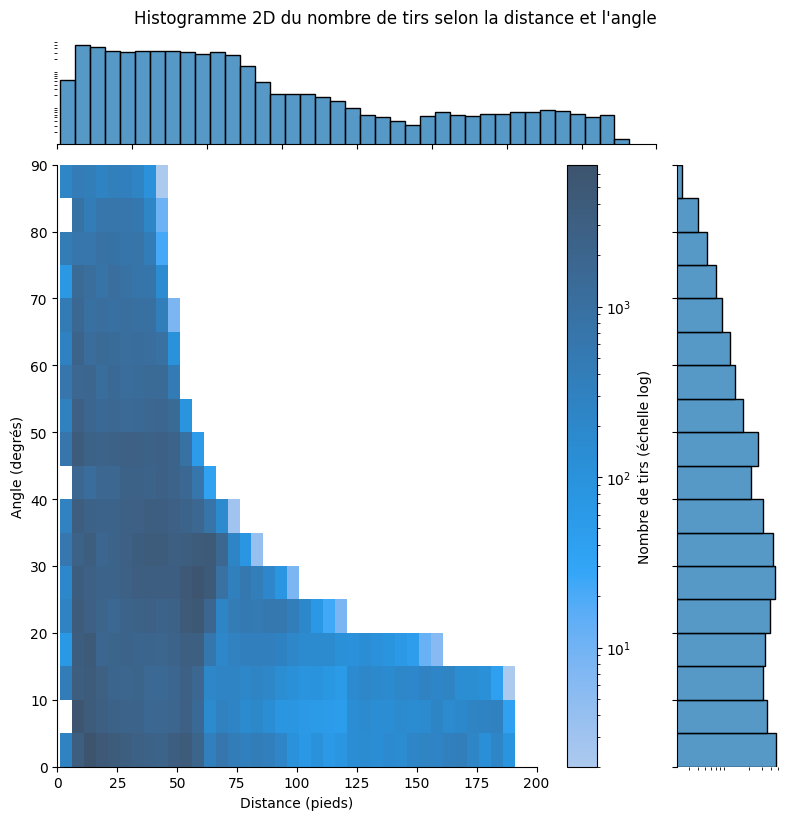

In [31]:
g = sns.jointplot(
    data=df_cols_imp_train,
    x="shot_distance",
    y="shot_angle",
    kind="hist",
    xlim=(0, 200),
    ylim=(0,90),
    height=8,
    # Fait des bins 5pieds*5degrés et ajoute la barre de couleur, LogNorm 
    # permet que l'échelle de couleur soit logarithmique. Vmin et Vmax doit 
    # être donné sinon le graphique ne s'affiche pas
    joint_kws={"binwidth": (5, 5), "cbar": True, "norm": LogNorm(), "vmin": None, "vmax": None, "cbar_kws": {"label": "Nombre de tirs (échelle log)"}},
    # Fait les même pas pour les hist marginaux
    marginal_kws={"binwidth": 5},
)
# Applique transformation log aux histogrammes marginaux
g.ax_marg_x.set_yscale("log")
g.ax_marg_y.set_xscale("log")
g.set_axis_labels("Distance (pieds)", "Angle (degrés)")
g.figure.suptitle("Histogramme 2D du nombre de tirs selon la distance et l'angle", y=1.02)
plt.show()

On remarque les mêmes résultats que nous avions vu avec les deux derniers histogrammes. Les tirs sont principalement concentrés dans des petites distances et angles.